# Fake News Detection — Phase 2: Vectorization & Model Training

**Project goal recap:** predict whether a news article is `Fake News` (1) or `Factual News` (0)
based on its text.

**This notebook = Phase 2.** It picks up exactly where Phase 1 left off: we load
`fake_news_data_clean.csv` (produced by `01_Data_Cleaning.ipynb`) and now actually train a model
on it.

**What's reused directly from the course (`02-Logistic_Regression_Project`):**
- `train_test_split(X, y, test_size=..., random_state=42)`
- `LogisticRegression()`, `.fit()`, `.predict()`
- `classification_report()` for evaluation

**What's new in this notebook (not covered in the course, since no course dataset was text):**
- `TfidfVectorizer` — turns cleaned article text into numeric features a model can use
- `confusion_matrix` + a heatmap plot of it (uses the same `seaborn`/`matplotlib` skills from the
  Matplotlib notebooks, just applied to a new kind of plot)
- `cross_val_score` — a sanity check appropriate for small datasets like ours (only 198 rows)

These new pieces are marked **[NEW]** in the section headers below.

## 0. Imports

In [2]:
# Core libraries (same as Phase 1 and the course's Logistic Regression Project)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Modeling tools from scikit-learn — train_test_split and LogisticRegression are the same
# ones used in 02-Logistic_Regression_Project. TfidfVectorizer is the new [NEW] piece needed
# because our input is raw text, not already-numeric columns.
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


## 1. Load the Cleaned Data

We load the OUTPUT of Phase 1 — `fake_news_data_clean.csv` — not the raw file. If this file is
missing or looks wrong, go back and re-run `01_Data_Cleaning.ipynb` first.

In [3]:
df = pd.read_csv('fake_news_data_clean.csv')
print('Shape:', df.shape)
df.head()

Shape: (198, 12)


,title,clean_title,text,clean_text,date,year,month,text_length,word_count,title_upper_ratio,fake_or_factual,label
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,hollyweird lib susan sarandon compares muslim ...,There are two small problems with your analogy...,two small problems analogy susan jesus muslim ...,2015-12-30,2015,12,1992,182,0.524590,Fake News,1
1,Elijah Cummings Called Trump Out To His Face A...,elijah cummings called trump face heres pathet...,Buried in Trump s bonkers interview with New Y...,buried trump bonkers interview new york times ...,2017-04-06,2017,4,2836,251,0.233766,Fake News,1
2,Hillary Clinton Says Half Her Cabinet Will Be ...,hillary clinton says half cabinet will women e...,"Women make up over 50 percent of this country,...",women make percent country grossly underrepres...,2016-04-26,2016,4,2220,196,0.196721,Fake News,1
3,Russian bombing of U.S.-backed forces being di...,russian bombing usbacked forces discussed high...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,washington reuters us defense secretary jim ma...,2017-09-18,2017,9,627,56,0.061538,Factual News,0
4,Britain says window to restore Northern Irelan...,britain says window restore northern ireland d...,BELFAST (Reuters) - Northern Ireland s politic...,belfast reuters northern ireland political par...,2017-09-04,2017,9,745,67,0.046154,Factual News,0


In [4]:
# Quick reminder of what we're working with: label balance should still be ~50/50
# (same check as Phase 1 — always confirm rather than assume)
df['label'].value_counts()

label
0    100
1     98
Name: count, dtype: int64

## 2. Choose Our Features (X) and Target (y)

This is the same `X` / `y` setup pattern as the course's Logistic Regression Project — `X` is
what we feed the model, `y` is what we want it to predict.

For `X`, we use `clean_text` (the cleaned article body from Phase 1) rather than the raw `text`
column, since `clean_text` is already lowercased, stripped of punctuation/stopwords, etc. —
exactly the preprocessing a text classifier expects.

In [5]:
X = df['clean_text']     # the cleaned article text — our input
y = df['label']           # 1 = Fake News, 0 = Factual News — what we're predicting

print('X sample:')
print(X.iloc[0][:200])
print()
print('y sample:', y.iloc[0])

X sample:
two small problems analogy susan jesus muslim joseph traveled bethlehem mary anyone paying attention don appear many female refugees accompanying male muslim refugees greecesusan sarandon spent christ

y sample: 1


## 3. Train/Test Split

Same function as the course (`train_test_split`), with one small but important addition for
this project: **`stratify=y`**.

**Why `stratify=y` matters here:** our dataset only has 198 rows — quite small. A plain random
split *could*, by chance, put far more Fake News articles in the training set and leave the test
set lopsided (e.g. 30 Fake / 10 Factual), which would make our evaluation results misleading.
`stratify=y` tells `train_test_split` to preserve the same Fake/Factual ratio in both the train
and test sets, matching the overall ~50/50 balance. This wasn't necessary in the course's
Advertising dataset (it was larger and the split didn't need this safeguard as much), but it's
good practice generally, and especially helpful here given how small our dataset is.

In [6]:
# test_size=0.2 means 20% of the data goes into the test set, 80% for training.
# random_state=42 makes the split reproducible — same as the course notebook.
# stratify=y keeps the Fake/Factual ratio consistent between train and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training set size:', X_train.shape[0])
print('Test set size:', X_test.shape[0])
print()
print('Training label balance:')
print(y_train.value_counts())
print()
print('Test label balance:')
print(y_test.value_counts())

Training set size: 158
Test set size: 40

Training label balance:
label
0    80
1    78
Name: count, dtype: int64

Test label balance:
label
0    20
1    20
Name: count, dtype: int64


## 4. [NEW] Vectorize the Text with TF-IDF

Models can't read words directly — everything has to become numbers. **TF-IDF**
(Term Frequency–Inverse Document Frequency) converts each article into a row of numbers, one
number per word in our vocabulary. The basic idea:

- A word that appears **often in one article** but **rarely across all articles** gets a
  **high** score (it's distinctive — useful for telling articles apart).
- A word that appears in **almost every article** (even after removing stopwords) gets a
  **low** score (it's not very useful for distinguishing one article from another).

This is exactly why TF-IDF usually works better than simple word counts (`CountVectorizer`) for
text classification — it automatically downweights generic words and upweights distinctive ones.

**Important:** we call `.fit()` (learn the vocabulary) only on the **training** data, then just
`.transform()` the test data using that same vocabulary. If we fit on the test data too, that
would be **data leakage** — letting the model 'see' information from the test set before
evaluation, which would make our results overly optimistic and unreliable.

In [7]:
# max_features=5000: cap the vocabulary at the 5000 most informative words, to keep things fast
# and avoid overfitting to extremely rare words.
# min_df=2: ignore words that appear in fewer than 2 articles — a word seen only once can't help
# the model generalize, it just adds noise.
tfidf = TfidfVectorizer(max_features=5000, min_df=2)

# Learn the vocabulary AND transform the training text in one step
X_train_tfidf = tfidf.fit_transform(X_train)

# Only transform the test text — using the vocabulary already learned from training data
X_test_tfidf = tfidf.transform(X_test)

print('Training TF-IDF matrix shape:', X_train_tfidf.shape)
print('Test TF-IDF matrix shape:', X_test_tfidf.shape)
print('Vocabulary size:', len(tfidf.vocabulary_))

Training TF-IDF matrix shape: (158, 3401)
Test TF-IDF matrix shape: (40, 3401)
Vocabulary size: 3401


The shape `(num_articles, vocabulary_size)` means: each article is now represented as a row of
numbers, one number per word in our learned vocabulary. This is the numeric format
`LogisticRegression` can actually train on.

## 5. Train the Logistic Regression Model

Same model and same `.fit()` call as `02-Logistic_Regression_Project` — just trained on our
TF-IDF features instead of numeric ad-click features.

In [8]:
# max_iter=1000: Logistic Regression sometimes needs more optimization steps to converge on
# text data (which has many features) than on the smaller numeric datasets from the course.
# random_state=42 again for reproducibility.
logreg = LogisticRegression(max_iter=1000, random_state=42)

logreg.fit(X_train_tfidf, y_train)

print('Model trained.')

Model trained.


## 6. Make Predictions on the Test Set

In [9]:
# Predict labels for the test articles (which the model has never seen)
y_pred = logreg.predict(X_test_tfidf)

# Compare a few actual vs. predicted labels side by side
comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
comparison.head(10)

,Actual,Predicted
0,0,0
1,1,1
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,1,0
8,1,1
9,0,0


## 7. Evaluate the Model

Same `classification_report` function used in the course's Logistic Regression Project.

In [10]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Test Accuracy: {accuracy:.2%}')
print()
print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['Factual News', 'Fake News']))

Test Accuracy: 95.00%

Classification Report:
              precision    recall  f1-score   support

Factual News       0.91      1.00      0.95        20
   Fake News       1.00      0.90      0.95        20

    accuracy                           0.95        40
   macro avg       0.95      0.95      0.95        40
weighted avg       0.95      0.95      0.95        40



**How to read this:**
- **Precision** — of the articles the model predicted as a class, what fraction actually were
  that class. High precision = few false alarms.
- **Recall** — of the articles that actually are a class, what fraction the model caught.
  High recall = few missed cases.
- **F1-score** — a balance between precision and recall.

Because our dataset is balanced (close to 50/50), plain accuracy is a reasonably trustworthy
headline number here — that wouldn't necessarily be true if one class were much rarer than the
other.

### [NEW] Confusion Matrix Heatmap

A confusion matrix shows exactly *which* mistakes the model made: how many Fake articles got
correctly called Fake, how many got wrongly called Factual, and vice versa. We visualize it with
`seaborn.heatmap`, using the same plotting tools from the Matplotlib course notebooks, just
applied to a new kind of chart.

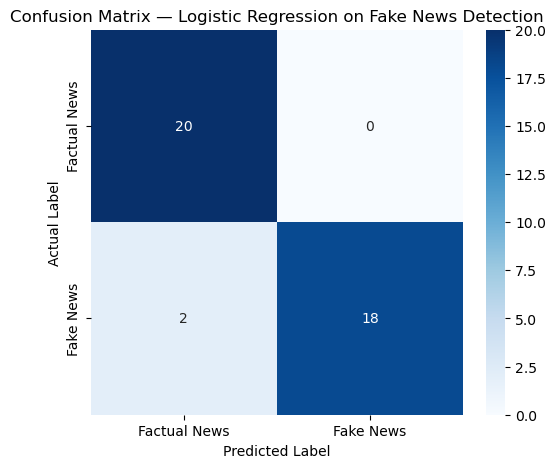

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Factual News', 'Fake News'],
            yticklabels=['Factual News', 'Fake News'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix — Logistic Regression on Fake News Detection')
plt.show()

## 8. [NEW] Cross-Validation Sanity Check

With only 198 rows, a single train/test split's accuracy number can be a bit noisy — we might
have gotten a particularly easy (or hard) test set just by chance. **Cross-validation** retrains
and re-tests the model 5 separate times, each time using a different slice of the data as the
test set, then averages the results. This gives a more trustworthy picture of how well the model
is really likely to perform, rather than relying on just one lucky/unlucky split.

In [12]:
# IMPORTANT: use SEPARATE vectorizer/model objects for cross-validation rather than reusing
# the main tfidf/logreg from Sections 4-5. If we called tfidf.fit_transform(X) here, it would
# silently refit the SAME tfidf object on the full dataset, changing its vocabulary size. That
# would then break Section 11's predict_article() function later, since logreg would still
# expect the original (training-only) vocabulary size, causing a feature-count mismatch.
# Keeping cv_tfidf/cv_model separate means tfidf/logreg stay untouched for prediction.
cv_tfidf = TfidfVectorizer(max_features=5000, min_df=2)
X_tfidf_full = cv_tfidf.fit_transform(X)

cv_model = LogisticRegression(max_iter=1000, random_state=42)
cv_scores = cross_val_score(cv_model, X_tfidf_full, y, cv=5)

print('Accuracy for each of the 5 folds:', cv_scores)
print(f'Mean CV Accuracy: {cv_scores.mean():.2%}')
print(f'Standard deviation: {cv_scores.std():.2%}')

Accuracy for each of the 5 folds: [1.         0.925      0.95       0.82051282 1.        ]
Mean CV Accuracy: 93.91%
Standard deviation: 6.60%


**Honest takeaway:** if the 5 fold scores vary quite a bit from each other (e.g. one fold at
100% and another at 80%), that's a sign our dataset is small enough that results can shift
depending on which articles happen to land in the test set. This doesn't mean the model is bad —
it just means we should treat any single accuracy number with a bit of healthy skepticism, and
see the mean CV accuracy as a more reliable estimate than any one split. A larger dataset in the
future would make this estimate more stable.

## 9. Look at What the Model Is Actually Learning

Logistic Regression assigns a weight (coefficient) to every word in the vocabulary. A strongly
positive weight means that word pushes the prediction toward **Fake News**; a strongly negative
weight pushes toward **Factual News**. Inspecting these helps us sanity-check whether the model
is learning something sensible — or just memorizing quirks of this particular small dataset.

In [13]:
feature_names = np.array(tfidf.get_feature_names_out())
coefficients = logreg.coef_[0]

# Words with the most positive coefficients -> strongest pull toward Fake News
top_fake_idx = np.argsort(coefficients)[-15:][::-1]
top_fake_words = feature_names[top_fake_idx]

# Words with the most negative coefficients -> strongest pull toward Factual News
top_factual_idx = np.argsort(coefficients)[:15]
top_factual_words = feature_names[top_factual_idx]

print('Top words pushing toward FAKE NEWS:')
print(list(top_fake_words))
print()
print('Top words pushing toward FACTUAL NEWS:')
print(list(top_factual_words))

Top words pushing toward FAKE NEWS:
['trump', 'clinton', 'don', 'just', 'go', 're', 'flynn', 'america', 'women', 'via', 'hillary', 'gop', 'school', 'like', 'cruz']

Top words pushing toward FACTUAL NEWS:
['said', 'reuters', 'us', 'minister', 'trumps', 'wednesday', 'tuesday', 'reporters', 'friday', 'washington', 'military', 'militants', 'budget', 'billion', 'court']


**A word of caution:** with only 198 articles, some of these 'top words' may just be quirks of
this specific small dataset (e.g. one particular article mentioning a specific place name many
times) rather than genuinely meaningful fake-vs-factual signals. This is a normal limitation of
small datasets, worth keeping in mind — and worth mentioning if asked about the model's
limitations in a report or presentation.

## 10. Look at the Mistakes

Inspecting exactly which articles the model got wrong is often more informative than any single
accuracy number — it tells us *what kind* of articles are hard for the model.

In [14]:
# Find which test articles were misclassified
misclassified_idx = X_test.index[y_test.values != y_pred]
misclassified_df = df.loc[misclassified_idx, ['title', 'label']].copy()
misclassified_df['predicted'] = y_pred[y_test.values != y_pred]
misclassified_df['label_name'] = misclassified_df['label'].map({1: 'Fake News', 0: 'Factual News'})
misclassified_df['predicted_name'] = misclassified_df['predicted'].map({1: 'Fake News', 0: 'Factual News'})

print(f'{len(misclassified_df)} out of {len(y_test)} test articles were misclassified:')
misclassified_df[['title', 'label_name', 'predicted_name']]

2 out of 40 test articles were misclassified:


,title,label_name,predicted_name
165,"NON-AMERICAN, Wife Of US Citizen ARRESTED In T...",Fake News,Factual News
150,RUSSIA’S STRANGE 45-ACRE MARYLAND COMPOUND Clo...,Fake News,Factual News


## 11. [NEW] Test the Model Yourself

Everything so far has evaluated the model on a fixed test set. This section adds a small,
reusable function — `predict_article(raw_text)` — so we (or our teammates building the API) can
paste in *any* headline or article text and immediately see what the model predicts, along with
its confidence.

**Why this matters for the handoff to Phase 3/4:** this is essentially a preview of what the API
will eventually do — take in raw text, run it through the same cleaning + vectorizing + predicting
pipeline, and return a label. Having it work here first, on known inputs, is a good sanity check
before anyone builds it into a service.


In [15]:
import re
import string

# Reuse the exact same cleaning logic from Phase 1 (01_Data_Cleaning.ipynb), so that any text
# we test here goes through the identical preprocessing the model was trained on. If the
# cleaning steps don't match, the vectorizer will see different-looking text than it learned
# from, and predictions become unreliable.

stop_words = set([
    'a', 'about', 'above', 'after', 'again', 'against', 'all', 'am', 'an', 'and', 'any', 'are',
    'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but',
    'by', 'could', 'did', 'do', 'does', 'doing', 'down', 'during', 'each', 'few', 'for', 'from',
    'further', 'had', 'has', 'have', 'having', 'he', 'her', 'here', 'hers', 'herself', 'him',
    'himself', 'his', 'how', 'i', 'if', 'in', 'into', 'is', 'it', 'its', 'itself', 'just', 'me',
    'more', 'most', 'my', 'myself', 'no', 'nor', 'not', 'now', 'of', 'off', 'on', 'once', 'only',
    'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 'same', 'she', 'should',
    'so', 'some', 'such', 'than', 'that', 'the', 'their', 'theirs', 'them', 'themselves', 'then',
    'there', 'these', 'they', 'this', 'those', 'through', 'to', 'too', 'under', 'until', 'up',
    'very', 'was', 'we', 'were', 'what', 'when', 'where', 'which', 'while', 'who', 'whom', 'why',
    'will', 'with', 'you', 'your', 'yours', 'yourself', 'yourselves'
])

def clean_text(text):
    """Same cleaning steps as Phase 1's clean_text(): lowercase, strip URLs/emails/HTML tags,
    strip punctuation (including curly quotes), strip digits, collapse whitespace, remove
    stopwords, drop single-character leftovers."""
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)               # URLs
    text = re.sub(r'\S+@\S+', ' ', text)                        # emails
    text = re.sub(r'<.*?>', ' ', text)                           # HTML tags
    punctuation_to_strip = string.punctuation + '‘’“”'  # incl. curly quotes
    text = text.translate(str.maketrans('', '', punctuation_to_strip))
    text = re.sub(r'\d+', ' ', text)                             # digits
    text = re.sub(r'\s+', ' ', text).strip()                     # collapse whitespace
    words = [w for w in text.split() if w not in stop_words and len(w) > 1]
    return ' '.join(words)


def predict_article(raw_text):
    """
    Takes a raw headline or article text (any string), runs it through the same cleaning +
    TF-IDF + Logistic Regression pipeline used for training, and prints the predicted label
    plus the model's confidence.

    Uses the SAME `tfidf` and `logreg` objects trained earlier in this notebook (Sections 4-5) —
    NOT the separate cv_tfidf/cv_model used only for cross-validation in Section 8. Keeping these
    separate matters: refitting `tfidf` on different data would silently change its vocabulary
    size, which breaks this function with a feature-count mismatch against `logreg`.
    """
    cleaned = clean_text(raw_text)
    vectorized = tfidf.transform([cleaned])

    prediction = logreg.predict(vectorized)[0]
    probabilities = logreg.predict_proba(vectorized)[0]

    label = 'Fake News' if prediction == 1 else 'Factual News'
    confidence = probabilities[prediction]

    print(f'Input text: "{raw_text[:100]}{"..." if len(raw_text) > 100 else ""}"')
    print(f'Cleaned text: "{cleaned[:100]}{"..." if len(cleaned) > 100 else ""}"')
    print(f'Predicted label: {label}')
    print(f'Confidence: {confidence:.1%}')

    return label, confidence


**Try it yourself:** paste any headline or article snippet into `predict_article(...)` below.


In [16]:
# Example: a neutral, real-sounding science headline
predict_article(
    "Scientists at a major university announced a new study showing promising early results "
    "for a treatment that could help patients recover faster, though researchers caution more "
    "trials are needed before any conclusions are drawn."
)


Input text: "Scientists at a major university announced a new study showing promising early results for a treatme..."
Cleaned text: "scientists major university announced new study showing promising early results treatment help patie..."
Predicted label: Fake News
Confidence: 51.9%


('Fake News', np.float64(0.5187519262878387))

**Result and what it means:** this particular example was predicted as Fake News with only
~52% confidence — essentially a coin flip. That's expected and worth stating honestly rather than
hiding: with only 198 training examples, the model hasn't seen nearly enough variety to be a
general-purpose detector. Low confidence on unfamiliar-style text is the model correctly
"shrugging" when it's unsure, not a bug. This is a useful talking point for any write-up or
presentation about the model's real-world limitations.

Feel free to try your own headlines in the cell above — both ones that sound clearly fake and
ones that sound clearly factual — to get a feel for where the model is confident and where it
isn't.


## Summary — What We Did in Phase 2

1. Loaded the cleaned dataset (`fake_news_data_clean.csv`) from Phase 1.
2. Set `X = clean_text`, `y = label`.
3. Split into train/test sets with `train_test_split(..., stratify=y)` — stratified because our
   dataset is small and we needed to guarantee balanced classes in both sets.
4. **[NEW]** Vectorized the text using `TfidfVectorizer`, fitting only on training data to avoid
   data leakage.
5. Trained a `LogisticRegression` model — same approach as the course's Logistic Regression
   Project, applied to text features instead of numeric ones.
6. Evaluated using `classification_report`, a confusion matrix heatmap, and 5-fold
   cross-validation (to get a more reliable performance estimate given the small dataset size).
7. Inspected the model's most influential words, and looked closely at the specific articles it
   got wrong.
8. **[NEW]** Built a reusable `predict_article(raw_text)` function so any new headline/article
   text can be run through the same cleaning + TF-IDF + Logistic Regression pipeline and get back
   a predicted label and confidence score — a small preview of what the eventual API will do.

**Result:** strong accuracy on this dataset, with the honest caveat that 198 rows is a small
sample — cross-validation gives a more trustworthy sense of real-world performance than any
single train/test split.

**Possible next steps (Phase 3, if you want to go further):**
- Try a different model for comparison (e.g. `MultinomialNB` — Naive Bayes is a classic, fast
  baseline for text classification).
- Try combining the TF-IDF text features with the extra numeric features from Phase 1
  (`text_length`, `word_count`, `title_upper_ratio`) using `scipy.sparse.hstack`.
- If more data becomes available, retrain and see if cross-validation scores become more stable.
- Try `GridSearchCV` to tune `TfidfVectorizer`/`LogisticRegression` hyperparameters more
  systematically rather than using the manually chosen settings above.